In [4]:
%load_ext autoreload
%autoreload 2

from pathlib import Path
import sys
path = str(Path(Path('File.py').parent.absolute()).parent.absolute())
sys.path.insert(0, path)

path = str(Path(Path('thermo.py').parent.absolute()).parent.absolute())
sys.path.insert(0, path)

import numpy as np
import matplotlib as mlab
import matplotlib.pyplot as plt
import scipy
import xarray as xr
import os as os
import glob
import matplotlib.gridspec as gridspec
import tools
from tools.FV3_tools import read_solo_fields, read_solo_w
from tools.CM1_tools import read_cm1_fields, read_cm1_w

from pltbook import nice_clevels, nice_mxmnintvl, container, plot_contour_row
from tools.CM1_tools import read_cm1_fields, read_cm1_w
from tools.FV3_tools import read_solo_fields, read_solo_w

import matplotlib.colors as mcolors

cmap_data = [(1.0,                1.0,                 1.0),
             (0.3137255012989044, 0.8156862854957581,  0.8156862854957581),
             (0.0,                1.0,                 1.0),
             (0.0,                0.8784313797950745,  0.501960813999176),
             (0.0,                0.7529411911964417,  0.0),
             (0.501960813999176,  0.8784313797950745,  0.0),
             (1.0,                1.0,                 0.0),
             (1.0,                0.6274510025978088,  0.0),
             (1.0,                0.0,                 0.0),
             (1.0,                0.125490203499794,   0.501960813999176),
             (0.9411764740943909, 0.250980406999588,   1.0),
             (0.501960813999176,  0.125490203499794,   1.0),
             (0.250980406999588,  0.250980406999588,   1.0),
             (0.125490203499794,  0.125490203499794,   0.501960813999176),
             (0.125490203499794,  0.125490203499794,   0.125490203499794),
             (0.501960813999176,  0.501960813999176,   0.501960813999176),
             (0.8784313797950745, 0.8784313797950745,  0.8784313797950745),
             (0.9333333373069763, 0.8313725590705872,  0.7372549176216125),
             (0.8549019694328308, 0.6509804129600525,  0.47058823704719543),
             (0.6274510025978088, 0.42352941632270813, 0.23529411852359772),
             (0.4000000059604645, 0.20000000298023224, 0.0)]

linestyle_tuple = [
     ('loosely dotted',        (0, (1, 10))),
     ('dotted',                (0, (1, 1))),
     ('densely dotted',        (0, (1, 1))),

     ('loosely dashed',        (0, (5, 10))),
     ('dashed',                (0, (5, 5))),
     ('densely dashed',        (0, (5, 1))),

     ('loosely dashdotted',    (0, (3, 10, 1, 10))),
     ('dashdotted',            (0, (3, 5, 1, 5))),
     ('densely dashdotted',    (0, (3, 1, 1, 1))),

     ('dashdotdotted',         (0, (3, 5, 1, 5, 1, 5))),
     ('loosely dashdotdotted', (0, (3, 10, 1, 10, 1, 10))),
     ('densely dashdotdotted', (0, (3, 1, 1, 1, 1, 1)))
]

_nthreads = 2

# draw filled contours

wclevs  = [0, 1, 2.5, 5, 7.5, 10, 15, 20, 30, 40, 50, 60, 70, 80]

scaled_wclevs = list(0.05 + 0.05*np.arange(26))

tclevs  = list(-40.0 + 2*np.arange(41))

pclevs  = list(-15.0 + np.arange(31))

dclevs  = list(-20.0 + np.arange(41))

zlevels = 25.0 + 60.*np.arange(300)

raw_cape = {"QV12": [915., 1430., 978.],
            "QV13": [1364.4, 1904., 1437.0],
            "QV14": [1872.2, 2354.1, 1953.3],
            "QV15": [2427.5, 2800.2, 2514.6], 
            "QV16": [ 3007.0, 3289.6,  3096.1] }

plotlabels = ["QV12", "QV14", "QV16"]

cape_mean = []
cape_mean = []

def geomean(cape):
    return (cape[0] * cape[1] * cape[2])**(1./3.)

for key in raw_cape:
   # cape_mean.append(geomean(raw_cape[key]))
    cape_mean.append(max(raw_cape[key]))

w_ideal = np.sqrt(2.0*np.array(cape_mean))

print(w_ideal)
print(cape_mean)

velocity_unicode = "m s\u207B\u00B9"
cape_unicode     = "J kg\u207B\u00B9"

def label_panels(axs, panel_labels, fontsize=14, adjust_loc=None):

    from operator import add

    base_loc = [0.025, 0.975]

    if adjust_loc:
        loc = list(map(add, base_loc, adjust_loc)) 
    else:
        loc = base_loc

    for i, ax in enumerate(axs.flatten()):
    # Add the panel label
        ax.text(*loc, panel_labels[i], transform=ax.transAxes, fontsize=fontsize, fontweight='medium', va='top', ha='left')

    return axs

solo   = '/work/wicker/climate_runs/FV3_Solo/bubble/euler/3km'
cm1     = '/work/wicker/climate_runs/cm1r20.3/run/bubble/3km'
cm1_w0 = '/work/wicker/climate_runs/cm1r20.3/run/bubble_WW0/3km'

s3 = []
c3 = []
c3_w0 = []


for key in plotlabels:  
    s3.append(read_solo_w(os.path.join(solo,key)))
    c3.append(read_cm1_w(os.path.join(cm1,key)))
    # c3_w0.append(read_cm1_w(os.path.join(cm1_w0,key)))
 

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
[53.47896783 61.70899448 68.61632459 74.8358203  81.11226788]
[1430.0, 1904.0, 2354.1, 2800.2, 3289.6]
------------------------------------------------------------------------------------------------------------------------
 Now reading... /work/wicker/climate_runs/FV3_Solo/bubble/euler/3km/QV12/atmos_hifreq.nc
 Completed reading: /work/wicker/climate_runs/FV3_Solo/bubble/euler/3km/QV12/atmos_hifreq.nc 

------------------------------------------------------------------------------------------------------------------------
 Now Reading:  /work/wicker/climate_runs/cm1r20.3/run/bubble/3km/QV12/cm1out.nc
 Completed reading: /work/wicker/climate_runs/cm1r20.3/run/bubble/3km/QV12/cm1out.nc 

------------------------------------------------------------------------------------------------------------------------
 Now reading... /work/wicker/climate_runs/FV3_Solo/bubble/euler/3km/QV14/atmos_hifreq.nc
 Compl

In [13]:
def plot_wmax(cmodel, smodel, res=3, subtitle='CM1 and FV3-SOLO', plot_type=0, smooth=0):
    
    if plot_type == 0:
        fig, ax  = plt.subplots(1,2, figsize=(16,8))
    else:
        fig, ax_one = plt.subplots(1,1, figsize=(8,8))
        
    linestyles = [':','--','solid'] 
    
    capes = [1085.672061987397, 2049.503665750544, 3128.6993610705954]

    #wscale = [46.59768368, 64.02349047, 79.10372129] 
    wscale = [53, 69, 81]

    cWmax = "CM1 Stats\n"
    sWmax = "FV3-Solo Stats\n"

    if plot_type == 0:

        for n, item in enumerate(cmodel):

            if smooth == 0:
                
                ax[0].plot(item.sec/60, item.w.max(axis=(1,2,3)), label=f"CM1 {int(capes[n])} {cape_unicode}", 
                           linestyle=linestyles[n], color='k')

            else:
                
                kernel = np.ones(smooth) / smooth

                smooth_w = np.convolve(item.w.max(axis=(1,2,3)), kernel, mode='same')
                ax[0].plot(item.sec/60, smooth_w, label=f"CM1 {int(capes[n])} {cape_unicode}", 
                           linestyle=linestyles[n], color='k')
                
        for n, item in enumerate(smodel):

            if smooth == 0:
                
                ax[0].plot(item.sec/60, item.w.max(axis=(1,2,3)), label=f"FV3-Solo CAPE: {int(capes[n])} {cape_unicode}", 
                           linestyle=linestyles[n], color='r')

            else:
                
                kernel = np.ones(smooth) / smooth

                smooth_w = np.convolve(item.w.max(axis=(1,2,3)), kernel, mode='same')
                ax[0].plot(item.sec/60, smooth_w, label=f"FV3-Solo CAPE: {int(capes[n])} {cape_unicode}",
                           linestyle=linestyles[n], color='r')
        
        
        ax[0].set_title(f'\u0394x = {res} KM: W Time Series for {subtitle}')
        ax[0].legend()
        ax[0].set_xlabel('Time (sec)')
        ax[0].set_ylabel('W (m/s)')
        ax[0].axvline(x=19., color='k', linestyle='solid', alpha=0.4)
        ax[0].set_xlim(0,60.)
        ax[0].set_ylim(0,70.)
        
    if plot_type == 0:
        
        ax1 = ax[1]
        
    else:
        
        ax1 = ax_one
        
    for n, item in enumerate(cmodel):
        if n == 0:
            linestyle = 'solid'
        else:
            linestyle = linestyle_tuple[n][1:][0]

        # cWmax = cWmax + f"\n Wscale: {int(wscale[n])} Wmax: {int(item.w.max())}"
        cWmax = cWmax + f"\n Max W: {int(item.w.max())} {velocity_unicode} "
            
        if smooth == 0:
                
            ax1.plot(item.sec/60, item.w.max(axis=(1,2,3))/wscale[n], label=f"CM1 CAPE: {int(capes[n])} {cape_unicode}", 
                     linestyle=linestyles[n], color='k')
        else:
            
            kernel = np.ones(smooth) / smooth

            end = smooth//2 + 1

            smooth_w = np.convolve(item.w.max(axis=(1,2,3)), kernel, mode='same')

            # this fixes the bad looking point due to truncation of convolve.
            smooth_w[-end::] = item.w.max(axis=(1,2,3))[-end::]
            
            ax1.plot(item.sec/60, smooth_w/wscale[n], label=f"CM1 CAPE: {int(capes[n])} {cape_unicode}", 
                     linestyle=linestyles[n], color='k')

    for n, item in enumerate(smodel):
        if n == 0:
            linestyle = 'solid'
        else:
            linestyle = linestyle_tuple[n][1:][0]

        # sWmax = sWmax + f"\n Wscale: {int(wscale[n])} Wmax: {int(item.w.max())}"
        sWmax = sWmax + f"\n Max W: {int(item.w.max())} {velocity_unicode} "
        
        if smooth == 0:
                
            ax1.plot(item.sec/60, item.w.max(axis=(1,2,3))/wscale[n], label=f"FV3-Solo CAPE: {int(capes[n])} {cape_unicode}", 
                     linestyle=linestyles[n], color='r')
        else:
            
            kernel = np.ones(smooth) / smooth

            end = smooth//2 + 1

            smooth_w = np.convolve(item.w.max(axis=(1,2,3)), kernel, mode='same')
            smooth_w[-end::] = item.w.max(axis=(1,2,3))[-end::]
            
            ax1.plot(item.sec/60, smooth_w/wscale[n], label=f"FV3-Solo CAPE: {int(capes[n])} {cape_unicode}", 
                     linestyle=linestyles[n], color='r')

# Add text box with info
    props = dict(boxstyle='square', facecolor='white', edgecolor='black')
    ax1.text(0.14, 0.92, cWmax, transform=ax1.transAxes,
        fontsize=10, verticalalignment='center', horizontalalignment='center',
        bbox=props)

    # Add text box with info
    props = dict(boxstyle='square', facecolor='white', edgecolor='black')
    ax1.text(0.14, 0.75, sWmax, transform=ax1.transAxes,
        fontsize=10, verticalalignment='center', horizontalalignment='center',
        bbox=props)

    ax1.set_xlim(0,60)
    ax1.set_ylim(0,1.2)
    ax1.axhline(y=0.9995, color='k', linestyle='solid', alpha=0.4)
    ax1.axhline(y=0.8, color='k', linestyle='--', alpha=0.4)
    ax1.axvline(x=19., color='k', linestyle='solid', alpha=0.4)
    ax1.set_title(f"\u0394x = {res} KM: Scaled W Time Series for {subtitle}")
    ax1.set_xlabel('Time (sec)')
    ax1.legend(loc='lower center', bbox_to_anchor=(0.525, 0.0), fontsize=10)
    ax1.set_ylabel('Fraction of Max W from Cape');

    return

# **3 km plots**

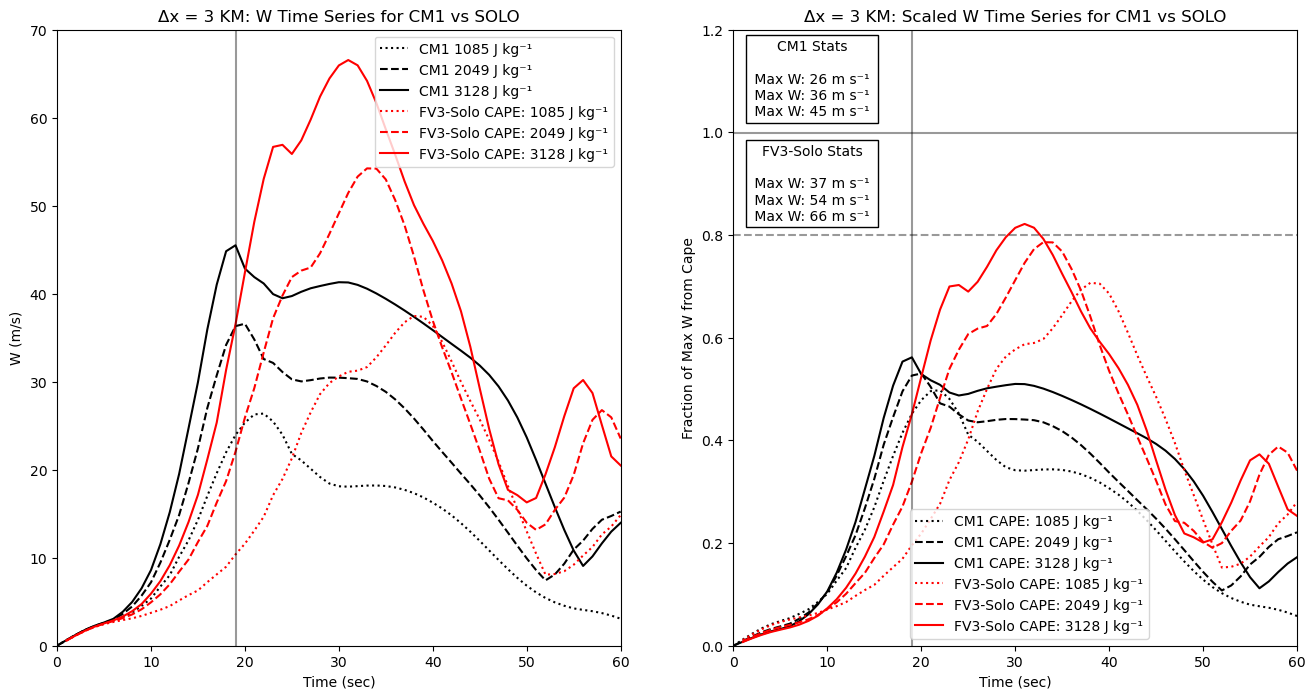

In [14]:

plot_wmax(c3, s3, res=3, subtitle='CM1 vs SOLO', plot_type=0)

plt.savefig("../Figures/Bubble_Wmax_TimeSeries_3km.pdf")
plt.savefig("../Figures/Bubble_Wmax_TimeSeries_3km.png")

#plot_wmax(c3, d3, res=3, subtitle='CM1 vs SOLO Reduced DIV')

# plot_wmax(c3_w0, s3, res=3, subtitle='CM1-NoWW vs SOLO-NO_COND', plot_type=1)
# plt.savefig("../Figures/Bubble_Wmax_CM-NoWW_3km.pdf")


# **1 km plots**

In [177]:
solo = '/work/wicker/climate_runs/FV3_Solo/bubble/euler_nocond/1km'
cm1  = '/work/wicker/climate_runs/cm1r20.3/run/bubble/1km'

s1  = []
c1  = []

for key in plotlabels:  
    s1.append(read_solo_w(os.path.join(solo,key)))
    c1.append(read_cm1_w(os.path.join(cm1,key)))

------------------------------------------------------------------------------------------------------------------------
 Now reading... /work/wicker/climate_runs/FV3_Solo/bubble/euler_nocond/1km/QV12/atmos_hifreq.nc
 Completed reading: /work/wicker/climate_runs/FV3_Solo/bubble/euler_nocond/1km/QV12/atmos_hifreq.nc 

------------------------------------------------------------------------------------------------------------------------
 Now Reading:  /work/wicker/climate_runs/cm1r20.3/run/bubble/1km/QV12/cm1out.nc
 Completed reading: /work/wicker/climate_runs/cm1r20.3/run/bubble/1km/QV12/cm1out.nc 

------------------------------------------------------------------------------------------------------------------------
 Now reading... /work/wicker/climate_runs/FV3_Solo/bubble/euler_nocond/1km/QV14/atmos_hifreq.nc
 Completed reading: /work/wicker/climate_runs/FV3_Solo/bubble/euler_nocond/1km/QV14/atmos_hifreq.nc 

--------------------------------------------------------------------------

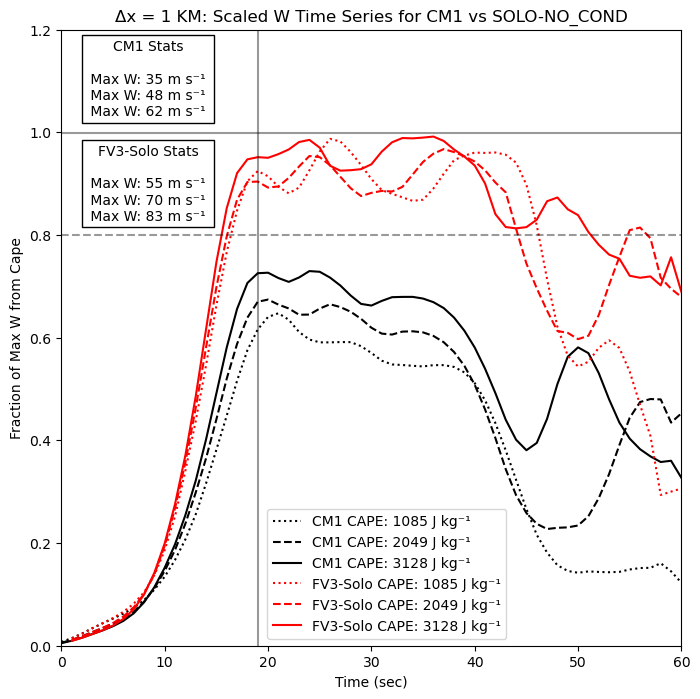

In [189]:

# plot_wmax(c1, s1, res=1, subtitle='CM1 vs SOLO-NO-COND', plot_type=1)

# # plt.savefig("../Figures/Figure11a_Bubble_Wmax_TimeSeries_1km.pdf")
# # plt.savefig("../Figures/Figure11a_Bubble_Wmax_TimeSeries_1km.png")

plot_wmax(c1, s1, res=1, subtitle='CM1 vs SOLO-NO_COND', plot_type=1, smooth=5)
plt.savefig("../Figures/Bubble_Wmax_TimeSeries_Smooth_1km_NO_COND.pdf")
plt.savefig("../Figures/Bubble_Wmax_TimeSeries_Smooth_1km_NO_COND.png")




In [179]:
solo = '/work/wicker/climate_runs/FV3_Solo/bubble/euler_nocond/500m'
cm1  = '/work/wicker/climate_runs/cm1r20.3/run/bubble/500m'

s5  = []
c5  = []

for key in plotlabels:  
    s5.append(read_solo_w(os.path.join(solo,key)))
    c5.append(read_cm1_w(os.path.join(cm1,key)))

------------------------------------------------------------------------------------------------------------------------
 Now reading... /work/wicker/climate_runs/FV3_Solo/bubble/euler_nocond/500m/QV12/atmos_hifreq.nc
 Completed reading: /work/wicker/climate_runs/FV3_Solo/bubble/euler_nocond/500m/QV12/atmos_hifreq.nc 

------------------------------------------------------------------------------------------------------------------------
 Now Reading:  /work/wicker/climate_runs/cm1r20.3/run/bubble/500m/QV12/cm1out.nc
 Completed reading: /work/wicker/climate_runs/cm1r20.3/run/bubble/500m/QV12/cm1out.nc 

------------------------------------------------------------------------------------------------------------------------
 Now reading... /work/wicker/climate_runs/FV3_Solo/bubble/euler_nocond/500m/QV14/atmos_hifreq.nc
 Completed reading: /work/wicker/climate_runs/FV3_Solo/bubble/euler_nocond/500m/QV14/atmos_hifreq.nc 

--------------------------------------------------------------------

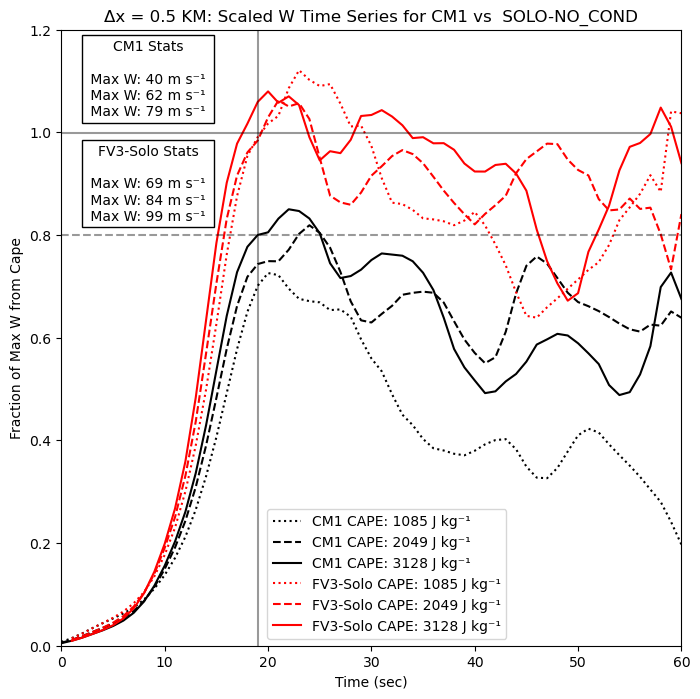

In [188]:
# plot_wmax(c5, s5, res=0.5, subtitle='CM1 vs SOLO-NO_COND', plot_type=1)

# plt.savefig("../Figures/Bubble_Wmax_TimeSeries_500m.pdf")
# plt.savefig("../Figures/Figure11b_Bubble_Wmax_TimeSeries_500m.png")

plot_wmax(c5, s5, res=0.5, subtitle='CM1 vs  SOLO-NO_COND', plot_type=1, smooth=5)

plt.savefig("../Figures/Bubble_Wmax_TimeSeries_Smooth_500m_NOCOND.pdf")
plt.savefig("../Figures/Bubble_Wmax_TimeSeries_Smooth_500m_NOCOND.png")

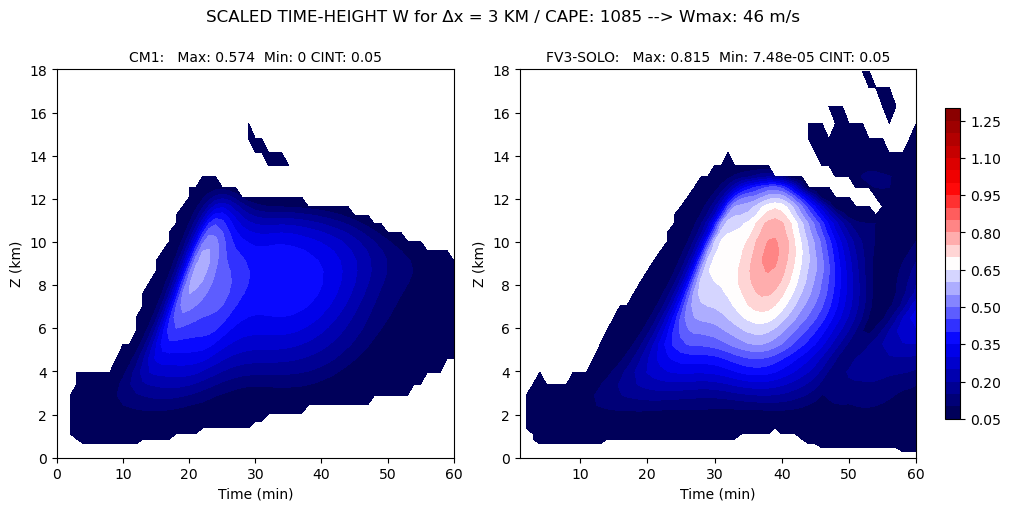

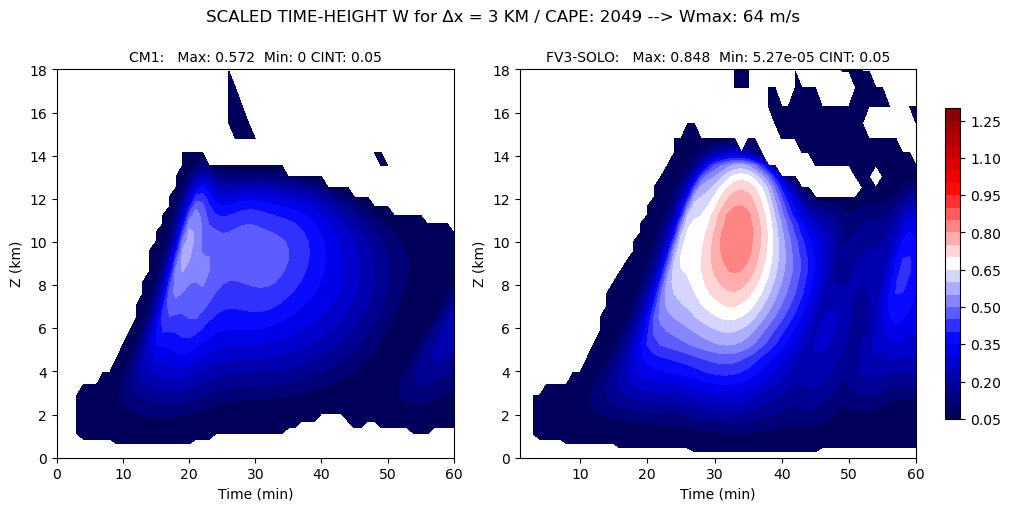

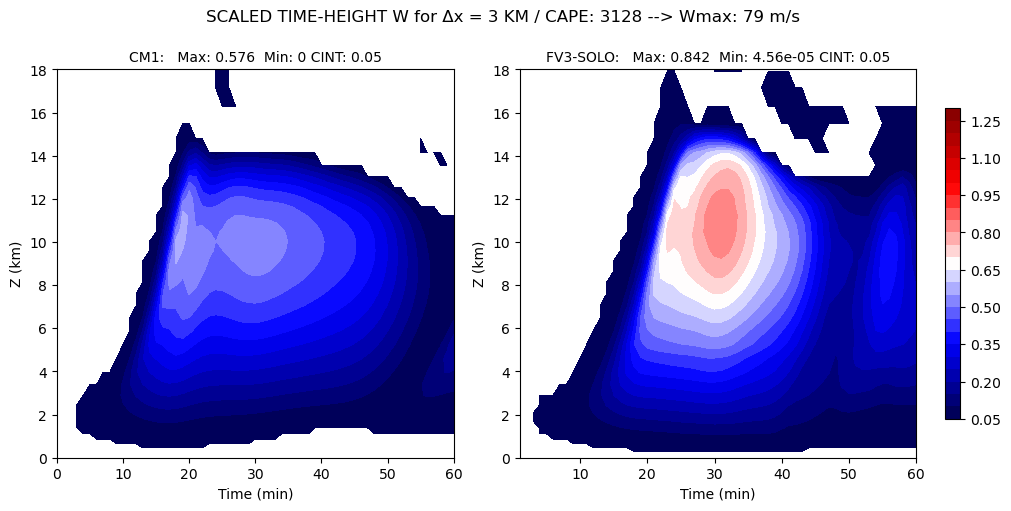

In [147]:
## 3 km plots

# for n, value in enumerate((1085, 2049, 3128)):

#     fields = []
#     fields.append(container(s3[n].w.max(axis=(2,3)).transpose(), s3[n].zc[0,:,0,0]/1000., s3[n].min))
#     fields.append(container(c3[n].w.max(axis=(2,3)).transpose(), s3[n].zc[0,:,0,0]/1000., c3[n].min))

#     plot_contour_row(fields, levels=wclevs, suptitle=f"DX = 3 KM:  CAPE: {value} J/kg", ptitle=['SOLO','CM1'], xlabel='Time (min)', ylabel='Z (km)', extra_levels=wclevs, 
#                  cmap=plt.cm.viridis_r, cint=2.5, ylim=(0,20.));

scaled_wclevs = list(0.05 + 0.05*np.arange(26))

cape = [1085, 2049, 3128]

#[53.47896783 61.70899448 68.61632459 74.8358203  81.11226788]

for n, value in enumerate((53, 69, 81)):

    fields = []
    fields.append(container(c3[n].w.max(axis=(2,3)).transpose()/value, s3[n].zc[0,:,0,0]/1000., c3[n].min, mask_out=[0.02, 2.0], cint=scaled_wclevs))
    fields.append(container(s3[n].w.max(axis=(2,3)).transpose()/value, s3[n].zc[0,:,0,0]/1000., s3[n].min, mask_out=[0.02, 2.0], cint=scaled_wclevs))

    ax = plot_contour_row(fields, plot_type=2,  color_levels=[0.05, 0.8, 1.5], 
                     cmap=plt.cm.seismic,  
                     suptitle=f"SCALED TIME-HEIGHT W for \u0394x = 3 KM / CAPE: {cape[n]} --> Wmax: {value} m/s \n",
                     ptitle=['CM1', 'FV3-SOLO'], xlabel='Time (min)', 
                     ylabel='Z (km)', ylim=(0,18.), mask_less=0.1, fancy_lw=True);

    plt.savefig(f"../Figures/Bubble_Scaled_TimeHeight_3km_Time{value:2d}_min.pdf")


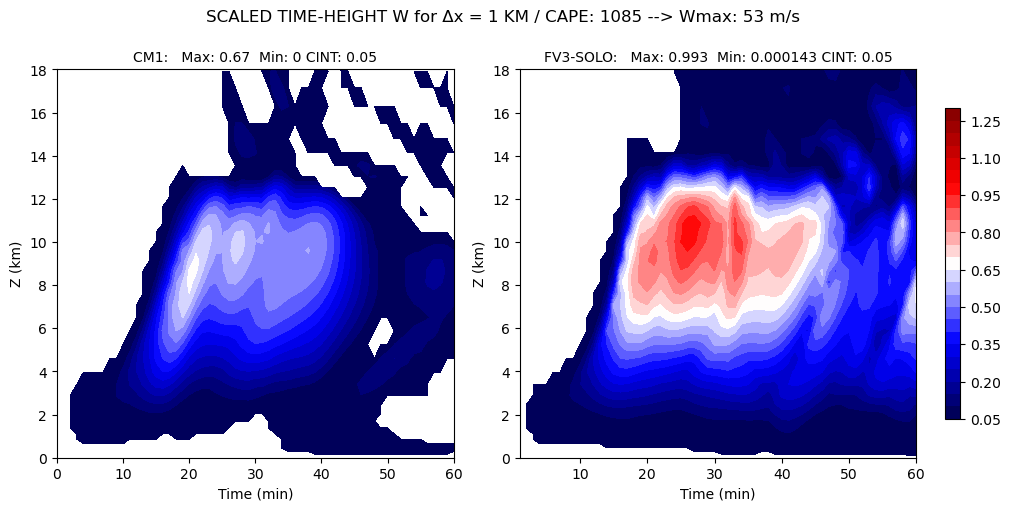

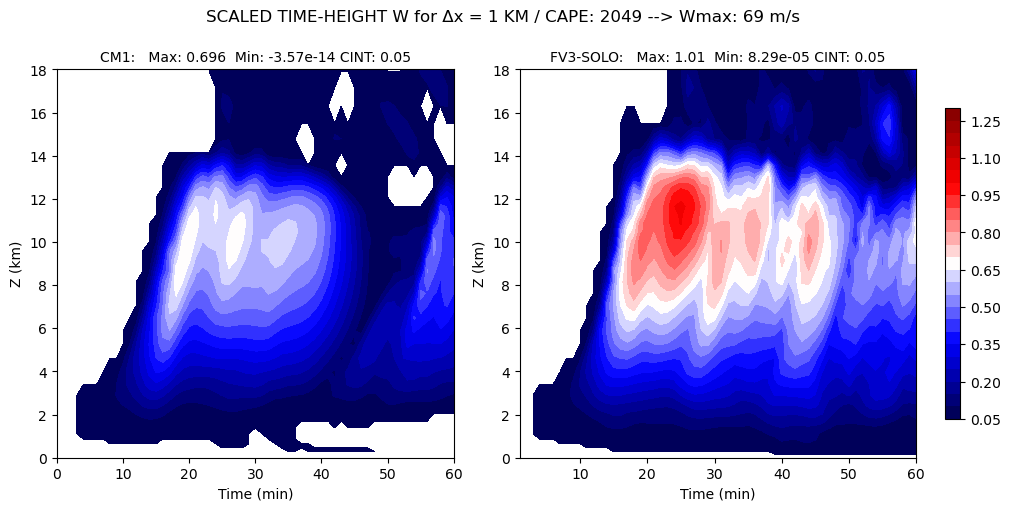

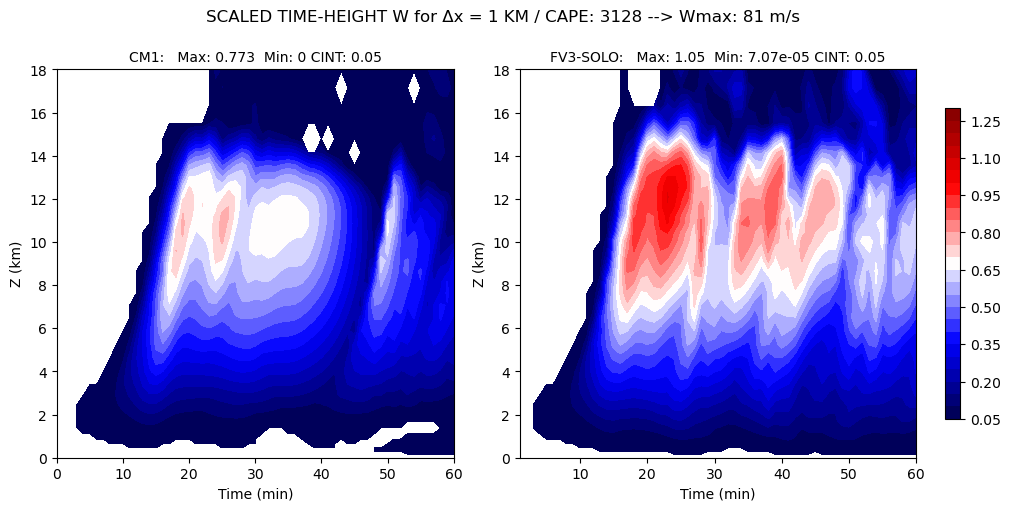

In [151]:
for n, value in enumerate((53, 69, 81)):

    fields = []
    fields = []
    fields.append(container(c1[n].w.max(axis=(2,3)).transpose()/value, s1[n].zc[0,:,0,0]/1000., c1[n].min, mask_out=[0.02, 2.0], cint=scaled_wclevs))
    fields.append(container(s1[n].w.max(axis=(2,3)).transpose()/value, s1[n].zc[0,:,0,0]/1000., s1[n].min, mask_out=[0.02, 2.0], cint=scaled_wclevs))

    plot_contour_row(fields, plot_type=2,  color_levels=[0.05, 0.8, 1.5], 
                     cmap=plt.cm.seismic,  
                     suptitle=f"SCALED TIME-HEIGHT W for \u0394x = 1 KM / CAPE: {cape[n]} --> Wmax: {value} m/s \n",
                     ptitle=['CM1', 'FV3-SOLO'], xlabel='Time (min)', 
                     ylabel='Z (km)', ylim=(0,18.), mask_less=0.1, fancy_lw=True);
    
    plt.savefig(f"../Figures/Bubble_Scaled_TimeHeight_1km_Time{value:2d}_min.pdf")


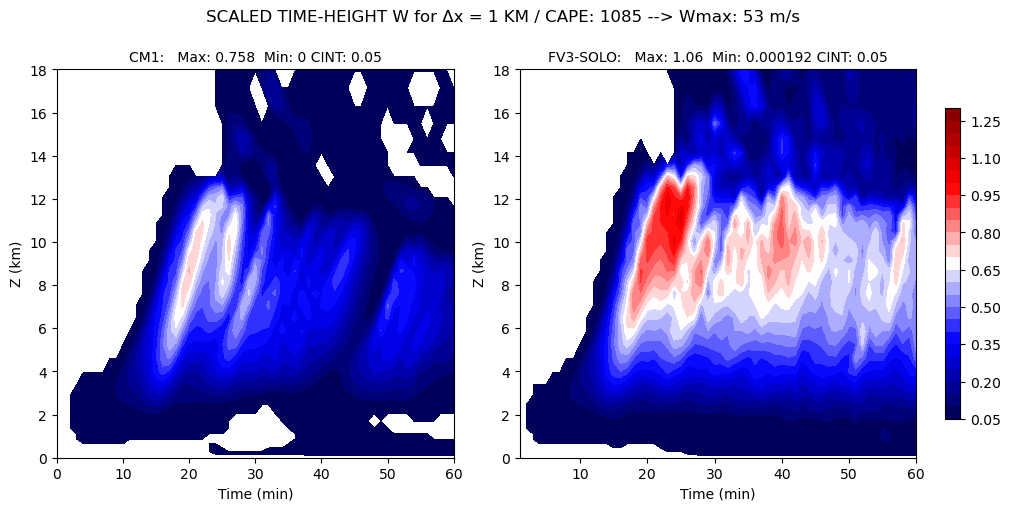

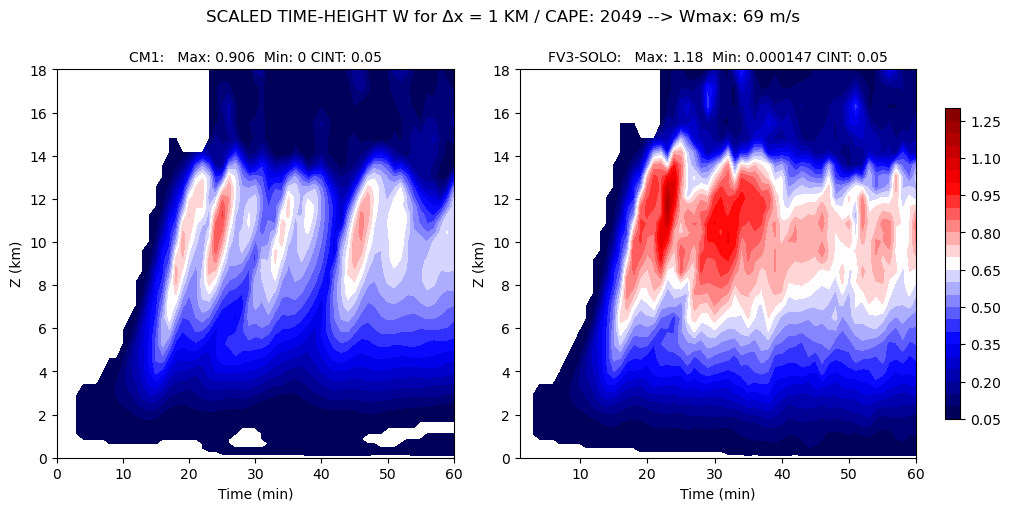

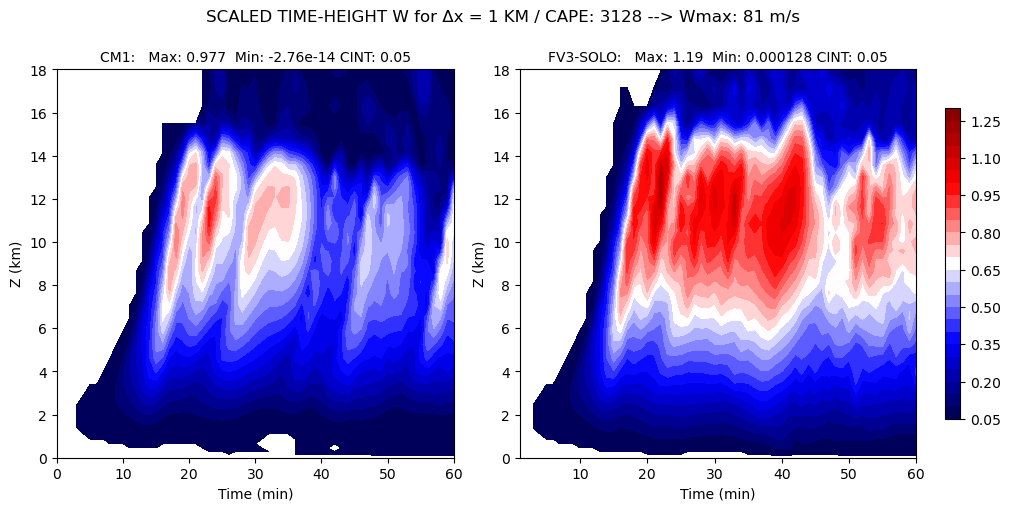

In [157]:
for n, value in enumerate((53, 69, 81)):

    fields = []
    fields = []
    fields.append(container(c5[n].w.max(axis=(2,3)).transpose()/value, c5[n].zc[0,:,0,0]/1000., c5[n].min, mask_out=[0.02, 2.0], cint=scaled_wclevs))
    fields.append(container(s5[n].w.max(axis=(2,3)).transpose()/value, s5[n].zc[0,:,0,0]/1000., s5[n].min, mask_out=[0.02, 2.0], cint=scaled_wclevs))

    plot_contour_row(fields, plot_type=2,  color_levels=[0.05, 0.8, 1.5], 
                     cmap=plt.cm.seismic,  
                     suptitle=f"SCALED TIME-HEIGHT W for \u0394x = 1 KM / CAPE: {cape[n]} --> Wmax: {value} m/s \n",
                     ptitle=['CM1', 'FV3-SOLO'], xlabel='Time (min)', 
                     ylabel='Z (km)', ylim=(0,18.), mask_less=0.1, fancy_lw=True);
    
    plt.savefig(f"../Figures/Bubble_Scaled_TimeHeight_500m_Time{value:2d}_min.pdf")